In [1]:
#imports
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
#reading file
base_path = Path.cwd().parent
df = pd.read_parquet(f"{base_path}/data/processed/clean_telemetry.parquet")

In [3]:
track = {"Rettifilo" : (130,185), "Roggia":(325,385) , "Lesmo":(405,530) , "Ascari" : (650 , 740) , "Parabolica" : (860,970)}
track_parts = []
for curve , (start , end) in track.items():
    curves = df["track_segment"].between(start , end)
    section = df[curves]
    mlData = section.groupby(["session" , "completedLaps"]).agg(min_speed = ("speedKmh" , min) , mean_speed=("speedKmh" , "mean") , exit_speed=("speedKmh" , "last"))
    mlData = mlData.add_prefix(f"{curve}_")
    track_parts.append(mlData)

monza = pd.concat(track_parts , axis=1)
print(monza)

                       Rettifilo_min_speed  Rettifilo_mean_speed  \
session completedLaps                                              
1       5                        64.864954            135.207599   
        6                        63.819803            140.879914   
        9                        52.487254            123.647865   
        12                       46.796174            130.210862   
        14                       63.439513            134.842782   
2       1                        45.883944            146.276441   
        5                        49.772368            143.101521   
        7                        49.682015            144.253993   
        8                        55.403060            142.872145   
        9                        52.975267            145.907932   
3       1                        53.325133            129.303800   
        2                        57.370324            143.336703   
        3                        52.025585      

In [4]:
X = monza
y = df.groupby(["session" , "completedLaps"])["cleanLaps"].first().round(3)
X_train  , X_test , y_train , y_test = train_test_split(X ,y , test_size=0.2 , random_state=42)
model_lr = LinearRegression()
model_lr.fit(X_train , y_train)
y_pred_lr = model_lr.predict(X_test)
mae_lr = mean_absolute_error(y_test , y_pred_lr)
r2_lr = r2_score(y_test , y_pred_lr)
cv_mae_rl = -cross_val_score(model_lr , X , y , cv=5 , scoring="neg_mean_absolute_error").mean()
print(mae_lr , r2_lr , cv_mae_rl)

0.7820976372134781 0.7949395369513674 1.1120742654370512


In [5]:
model_rf = RandomForestRegressor(random_state=42)
model_rf.fit(X_train , y_train)
y_pred_rf = model_rf.predict(X_test)
mae_rf = mean_absolute_error(y_test , y_pred_rf)
r2_rf = r2_score(y_test , y_pred_rf)
cv_mae_rf = -cross_val_score(model_rf , X , y , cv=5 , scoring="neg_mean_absolute_error").mean()
print(mae_rf , r2_rf , cv_mae_rf)


1.5467999999999782 0.4386551704188961 0.8957045714285709


In [6]:
model_gb = GradientBoostingRegressor(random_state=42)
model_gb.fit(X_train , y_train)
y_pred_gb = model_gb.predict(X_test)
mae_gb = mean_absolute_error(y_test , y_pred_gb)
r2_gb = r2_score(y_test , y_pred_gb)
cv_mae_gb = -cross_val_score(model_gb , X , y , cv=5 , scoring="neg_mean_absolute_error").mean()
print(mae_gb , r2_gb , cv_mae_gb)


1.3489488262952076 0.5030922588593794 1.0012118657216225


               Model       MAE        R2    CV_MAE
0  Linear Regression  0.782098  0.794940  1.112074
1      Random Forest  1.546800  0.438655  0.895705
2  Gradient Boosting  1.348949  0.503092  1.001212


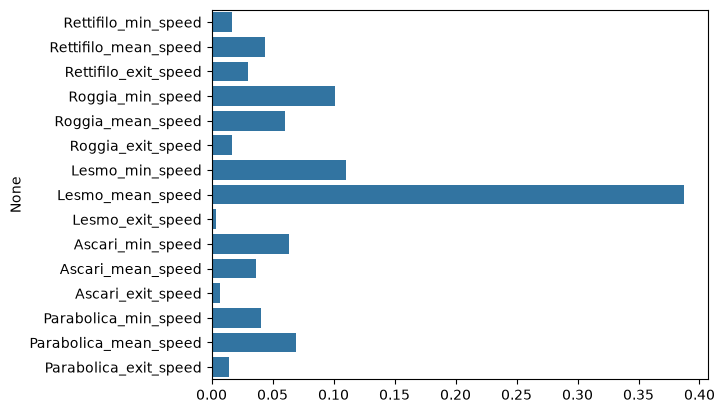

In [ ]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "Gradient Boosting"],
    "MAE": [mae_lr, mae_rf, mae_gb],
    "R2": [r2_lr, r2_rf, r2_gb],
    "CV_MAE": [cv_mae_rl, cv_mae_rf, cv_mae_gb],
})
sns.barplot(x=model_rf.feature_importances_, y=X.columns )
print(results)
plt.title("How much each charastetic affected laptime")
plt.show()
